# Quy trình tiền xử lý dữ liệu Bank Marketing (Loại bỏ Data Leakage)

Notebook này thực hiện tuần tự quy trình tiền xử lý dữ liệu chuẩn hóa, khắc phục triệt để lỗi **Data Leakage (Rò rỉ dữ liệu)**:
1. **Làm sạch tĩnh**: Kiểm tra cấu trúc dữ liệu, xóa trùng lặp và ánh xạ các biến nhị phân, thứ tự, thời gian cố định.
2. **Chia tập dữ liệu sớm (`train_test_split`)**: Ngăn ngừa rò rỉ dữ liệu từ tập test vào tập train.
3. **EDA & Trực quan hóa**: Chỉ tính toán và biểu diễn phân phối dựa trên `X_train` (và `y_train`).
4. **Xây dựng `ColumnTransformer` & `Pipeline`**: Đóng gói `SimpleImputer`, `IQRCapper` (custom transformer), `RobustScaler`, và `OneHotEncoder` — chỉ `fit` trên tập Train, sau đó `transform` cho cả Train và Test.
5. **Xử lý mất cân bằng lớp (`SMOTE`)**: Chỉ áp dụng trên `X_train_processed` và `y_train`.
6. **Xuất dữ liệu**: Lưu riêng các tập dữ liệu sạch `train_processed.csv`, `train_resampled.csv`, và `test_processed.csv`.


## Bước 1 - Tải dữ liệu & làm sạch tĩnh (Trước khi chia train/test)

Khai báo các thư viện cần thiết, thiết lập cấu hình hiển thị và đọc dữ liệu từ `bank-full.csv`.
Tại bước này, chúng ta chỉ thực hiện các phép biến đổi mang tính chất tĩnh, không phụ thuộc vào phân phối hay thống kê của dữ liệu (như xóa trùng lặp và ánh xạ từ điển cố định).


In [1]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from imblearn.over_sampling import SMOTE

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

PLOT_DIR = Path("./outputs/plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
data = pd.read_csv("./bank-full.csv", sep=";")
print("5 dòng đầu:")
display(data.head())
print("5 dòng cuối:")
display(data.tail())
print(f"Kích thước ban đầu: {data.shape[0]:,} dòng x {data.shape[1]} cột")
print("\nThông tin tổng quát:")
data.info()
print("\nKiểu dữ liệu từng cột:")
display(data.dtypes.to_frame("dtype"))


5 dòng đầu:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


5 dòng cuối:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


Kích thước ban đầu: 45,211 dòng x 17 cột

Thông tin tổng quát:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Kiểu dữ liệu từng cột:


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


Xử lý dữ liệu trùng lặp và thực hiện ánh xạ cố định (nhị phân, thứ tự, tháng). Các quy tắc ánh xạ này là cố định theo định nghĩa bài toán, hoàn toàn độc lập với phân phối của dữ liệu:
- Các cột nhị phân `["default", "housing", "loan", "y"]` $\rightarrow$ `{"no": 0, "yes": 1}`.
- Cột thứ tự `education` $\rightarrow$ `{"unknown": 0, "primary": 1, "secondary": 2, "tertiary": 3}`.
- Cột thời gian `month` $\rightarrow$ `{"jan": 1, ..., "dec": 12}`.


In [3]:
# Xóa các dòng trùng lặp
duplicate_count = int(data.duplicated().sum())
print(f"Số dòng trùng lặp: {duplicate_count:,}")
data = data.drop_duplicates().reset_index(drop=True)
print(f"Kích thước sau drop_duplicates: {data.shape[0]:,} dòng x {data.shape[1]} cột")

# Ánh xạ các cột nhị phân, thứ tự, thời gian
for column in ["default", "housing", "loan", "y"]:
    data[column] = data[column].map({"no": 0, "yes": 1}).astype("int8")

data["education"] = data["education"].map(
    {"unknown": 0, "primary": 1, "secondary": 2, "tertiary": 3}
).astype("int8")

data["month"] = data["month"].map(
    {
        "jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
        "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12,
    }
).astype("int8")

print("Đã hoàn thành ánh xạ tĩnh các cột: default, housing, loan, y, education, month")
display(data.head())


Số dòng trùng lặp: 0
Kích thước sau drop_duplicates: 45,211 dòng x 17 cột
Đã hoàn thành ánh xạ tĩnh các cột: default, housing, loan, y, education, month


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,3,0,2143,1,0,unknown,5,5,261,1,-1,0,unknown,0
1,44,technician,single,2,0,29,1,0,unknown,5,5,151,1,-1,0,unknown,0
2,33,entrepreneur,married,2,0,2,1,1,unknown,5,5,76,1,-1,0,unknown,0
3,47,blue-collar,married,0,0,1506,1,0,unknown,5,5,92,1,-1,0,unknown,0
4,33,unknown,single,0,0,1,0,0,unknown,5,5,198,1,-1,0,unknown,0


## Bước 2 - Chia tập dữ liệu (train_test_split sớm để chống Data Leakage)

**Nguyên tắc cốt lõi**: Tách tập `train/test` sớm nhất có thể. Mọi tham số thống kê (như `median`, `mode`, phân vị `Q1, Q3`, `IQR`, thang đo `RobustScaler`, và từ điển các danh mục `OneHotEncoder`) **bắt buộc chỉ được học từ `X_train`**. Tập `X_test` phải đóng vai trò là dữ liệu mới hoàn toàn chưa từng thấy trong thực tế (unseen data).

Sử dụng `stratify=y` để bảo toàn tỷ lệ lớp nhãn ở cả 2 tập.


In [4]:
X = data.drop(columns="y")
y = data["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print(f"Kích thước tập Train (X_train): {X_train.shape[0]:,} dòng x {X_train.shape[1]} cột")
print(f"Kích thước tập Test  (X_test):  {X_test.shape[0]:,} dòng x {X_test.shape[1]} cột")
print(f"Số lượng nhãn y_train:          {y_train.shape[0]:,} nhãn")
print(f"Số lượng nhãn y_test:           {y_test.shape[0]:,} nhãn")


Kích thước tập Train (X_train): 36,168 dòng x 16 cột
Kích thước tập Test  (X_test):  9,043 dòng x 16 cột
Số lượng nhãn y_train:          36,168 nhãn
Số lượng nhãn y_test:           9,043 nhãn


## Bước 3 - Khám phá dữ liệu (EDA) & Trực quan hóa trên tập Train

Tất cả các biểu đồ và phân tích bên dưới chỉ được thực hiện trên `X_train` (và `y_train`) để tránh "nhìn trộm" dữ liệu test:
1. **Kiểm tra missing & unknown**: Giá trị thiếu thực tế (`null`) và giá trị `unknown`. Trong dataset này, `unknown` ở các cột phân loại mang thông tin hữu ích và sẽ được bảo toàn thông qua `OneHotEncoder`.
2. **Phát hiện ngoại lệ (Outliers)**: Dùng boxplot quan sát phân phối của các biến số trên tập Train trước khi thực hiện capping.


Báo cáo Null/unknown trên tập Train:


,null_count,unknown_count,total_missing_or_unknown,percentage
poutcome,0,29589,29589,81.809887
contact,0,10386,10386,28.715992
education,0,1482,1482,4.097545
job,0,234,234,0.646981
default,0,0,0,0.000000
balance,0,0,0,0.000000
age,0,0,0,0.000000
marital,0,0,0,0.000000
loan,0,0,0,0.000000
housing,0,0,0,0.000000


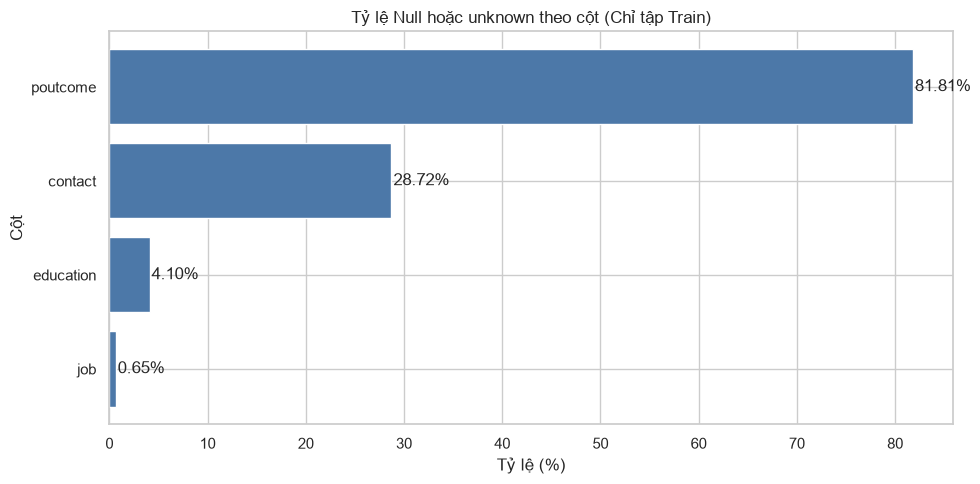

In [5]:
# Báo cáo missing và unknown trên tập Train
null_count = X_train.isna().sum()
unknown_count = X_train.eq("unknown").sum()
if "education" in X_train.columns:
    unknown_count["education"] = (X_train["education"] == 0).sum()

missing_report = pd.DataFrame(
    {
        "null_count": null_count,
        "unknown_count": unknown_count,
        "total_missing_or_unknown": null_count + unknown_count,
    }
)
missing_report["percentage"] = (
    missing_report["total_missing_or_unknown"] / len(X_train) * 100
)
print("Báo cáo Null/unknown trên tập Train:")
display(missing_report.sort_values("total_missing_or_unknown", ascending=False))

plot_report = missing_report[
    missing_report["total_missing_or_unknown"] > 0
].sort_values("percentage")
plt.figure(figsize=(10, 5))
bars = plt.barh(plot_report.index, plot_report["percentage"], color="#4C78A8")
plt.title("Tỷ lệ Null hoặc unknown theo cột (Chỉ tập Train)")
plt.xlabel("Tỷ lệ (%)")
plt.ylabel("Cột")
for bar, value in zip(bars, plot_report["percentage"]):
    plt.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
    )
plt.tight_layout()
plt.savefig(PLOT_DIR / "01_missing_unknown_rate.png", dpi=150, bbox_inches="tight")
plt.show()


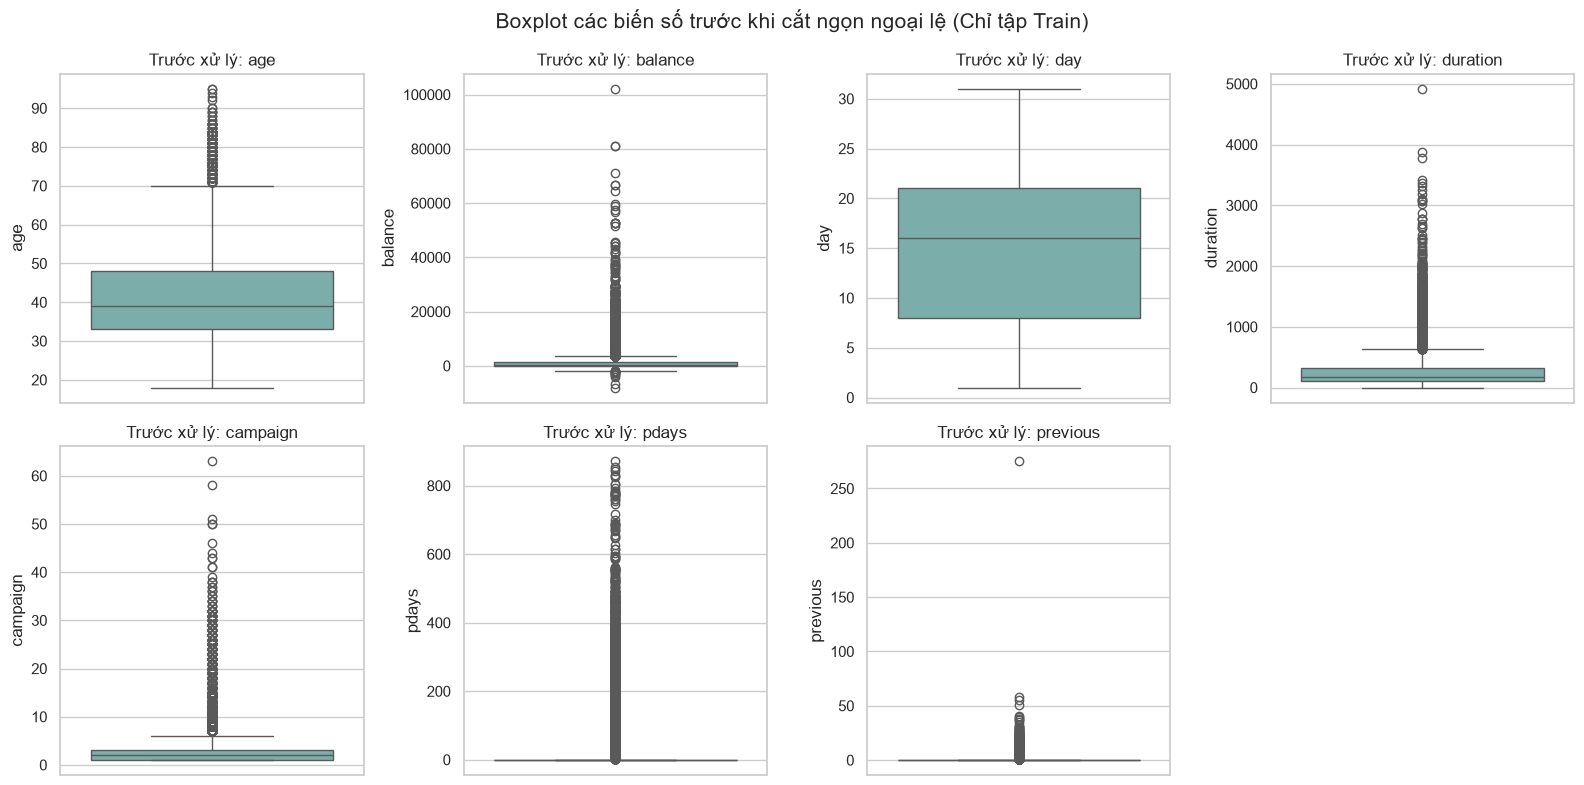

In [6]:
numeric_columns = [
    "age", "balance", "day", "duration", "campaign", "pdays", "previous"
]
capping_columns = ["age", "balance", "day", "duration", "campaign"]
other_numeric_columns = ["pdays", "previous"]
categorical_columns = ["job", "marital", "contact", "poutcome"]

# Boxplot các biến số trên tập Train trước khi capping
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis, column in zip(axes.flat, numeric_columns):
    sns.boxplot(y=X_train[column], ax=axis, color="#72B7B2")
    axis.set_title(f"Trước xử lý: {column}")
    axis.set_ylabel(column)
axes.flat[-1].axis("off")
fig.suptitle("Boxplot các biến số trước khi cắt ngọn ngoại lệ (Chỉ tập Train)", fontsize=15)
plt.tight_layout()
plt.savefig(PLOT_DIR / "02_outliers_before_capping.png", dpi=150, bbox_inches="tight")
plt.show()


## Bước 4 - Xây dựng ColumnTransformer & Pipeline (Fit trên Train, Transform trên Test)

Để đóng gói toàn bộ quy trình tiền xử lý theo chuẩn của `scikit-learn`:
- Xây dựng transformer tùy chỉnh `IQRCapper`: học ngưỡng $Q1, Q3$ và khoảng $IQR$ từ tập train trong `fit()`, và dùng các ngưỡng này để clip giá trị trong `transform()` cho cả train và test.
- Đóng gói vào `ColumnTransformer`:
  - `num_capped`: `SimpleImputer(strategy="median")` $\rightarrow$ `IQRCapper(factor=1.5)` $\rightarrow$ `RobustScaler()`
  - `num_other`: `SimpleImputer(strategy="median")` $\rightarrow$ `RobustScaler()`
  - `cat_ohe`: `SimpleImputer(strategy="most_frequent")` $\rightarrow$ `OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.int8)`
  - `remainder="passthrough"` giữ nguyên các cột đã map tĩnh ở Bước 1.
- Cấu hình `preprocessor.set_output(transform="pandas")` để giữ nguyên tên cột dưới dạng DataFrame.
- Gọi `fit_transform(X_train)` và **chỉ gọi `transform(X_test)`**.


In [7]:
class IQRCapper(BaseEstimator, TransformerMixin):
    """Chỉ học ngưỡng Q1, Q3 từ tập train và áp dụng clip cho cả train/test."""

    def __init__(self, factor: float = 1.5) -> None:
        self.factor = factor

    def fit(self, X: pd.DataFrame | np.ndarray, y=None) -> "IQRCapper":
        if isinstance(X, pd.DataFrame):
            self.feature_names_in_ = np.asarray(X.columns, dtype=str)
        X_arr = np.asarray(X, dtype=float)
        q1 = np.nanpercentile(X_arr, 25, axis=0)
        q3 = np.nanpercentile(X_arr, 75, axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.factor * iqr
        self.upper_ = q3 + self.factor * iqr
        return self

    def transform(self, X: pd.DataFrame | np.ndarray) -> np.ndarray:
        X_arr = np.asarray(X, dtype=float)
        return np.clip(X_arr, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None) -> np.ndarray:
        if input_features is not None:
            return np.asarray(input_features, dtype=str)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_
        return None

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num_capped",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("capper", IQRCapper(factor=1.5)),
                    ("scaler", RobustScaler()),
                ]
            ),
            capping_columns,
        ),
        (
            "num_other",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", RobustScaler()),
                ]
            ),
            other_numeric_columns,
        ),
        (
            "cat_ohe",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "encoder",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            sparse_output=False,
                            dtype=np.int8,
                        ),
                    ),
                ]
            ),
            categorical_columns,
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

preprocessor.set_output(transform="pandas")

# Fit và transform trên tập Train, CHỈ transform trên tập Test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Kích thước X_train sau pipeline: {X_train_processed.shape}")
print(f"Kích thước X_test sau pipeline:  {X_test_processed.shape}")


Kích thước X_train sau pipeline: (36168, 34)
Kích thước X_test sau pipeline:  (9043, 34)


Trực quan hóa và đánh giá hiệu quả của các bước tiền xử lý trên tập Train:
- Ngưỡng capping và boxplot sau capping theo IQR.
- Số lượng cột trước và sau One-Hot Encoding.
- Phân phối trước và sau `RobustScaler`.
- Ma trận tương quan Pearson và phân tích đa cộng tuyến (trên `X_train_processed` kết hợp `y_train`).


Số ngoại lệ trên tập Train trước capping (ngưỡng học từ Train):


age          394
balance     3770
day            0
duration    2632
campaign    2465
Name: số ngoại lệ trước capping, dtype: int64

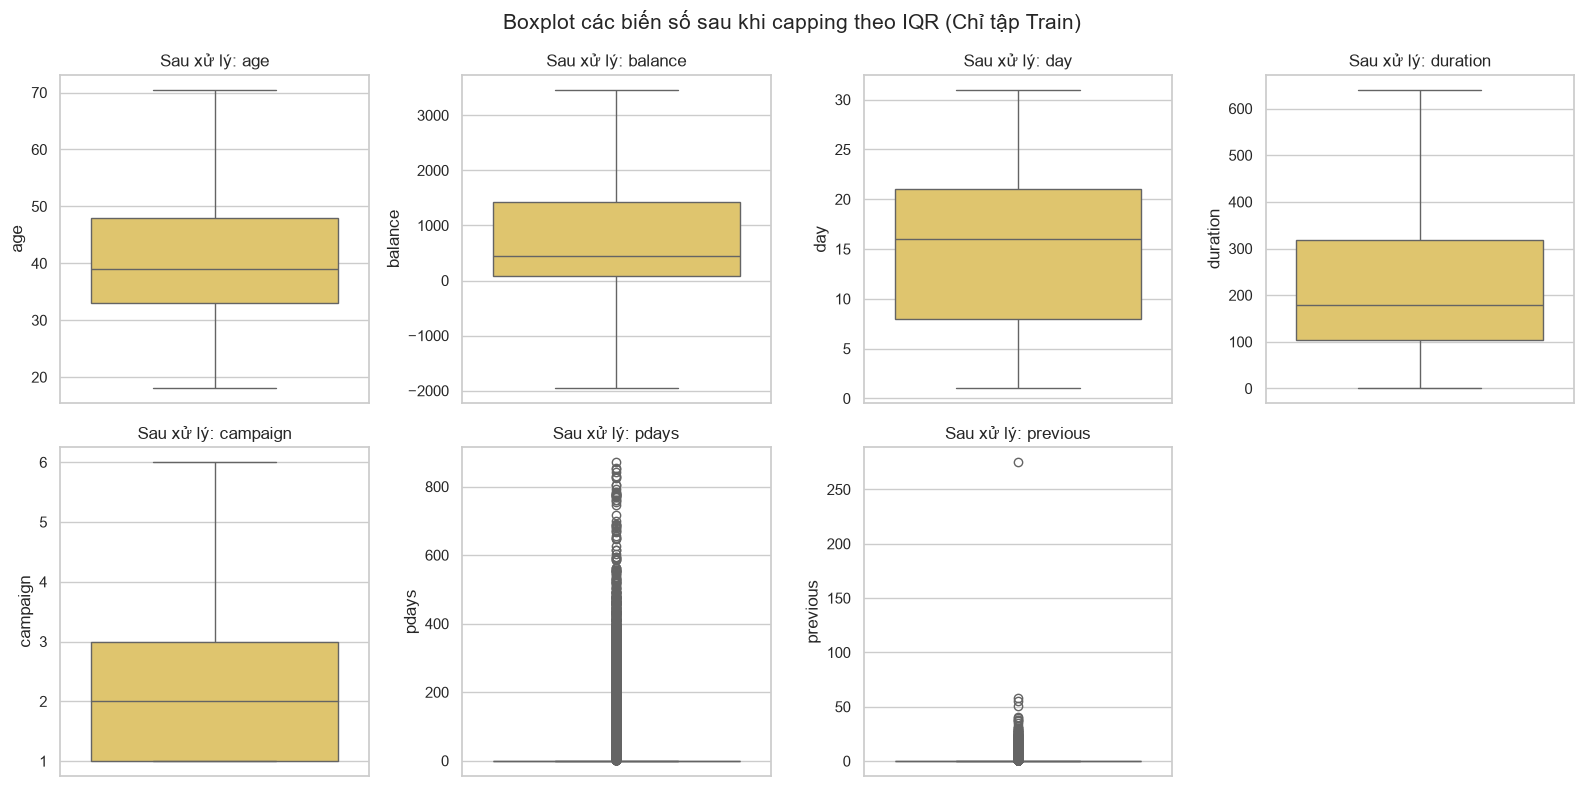

In [8]:
# Trích xuất thông số capper đã học từ tập Train
capper = preprocessor.named_transformers_["num_capped"].named_steps["capper"]
outlier_summary = {}
for idx, column in enumerate(capping_columns):
    lower = capper.lower_[idx]
    upper = capper.upper_[idx]
    outlier_summary[column] = int(
        ((X_train[column] < lower) | (X_train[column] > upper)).sum()
    )
print("Số ngoại lệ trên tập Train trước capping (ngưỡng học từ Train):")
display(pd.Series(outlier_summary, name="số ngoại lệ trước capping"))

# Boxplot các biến số sau khi capping theo IQR (chỉ tập Train)
X_train_capped = X_train[numeric_columns].copy()
X_train_capped[capping_columns] = np.clip(
    X_train[capping_columns].to_numpy(dtype=float), capper.lower_, capper.upper_
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis, column in zip(axes.flat, numeric_columns):
    sns.boxplot(y=X_train_capped[column], ax=axis, color="#F2CF5B")
    axis.set_title(f"Sau xử lý: {column}")
    axis.set_ylabel(column)
axes.flat[-1].axis("off")
fig.suptitle("Boxplot các biến số sau khi capping theo IQR (Chỉ tập Train)", fontsize=15)
plt.tight_layout()
plt.savefig(PLOT_DIR / "03_outliers_after_capping.png", dpi=150, bbox_inches="tight")
plt.show()


Số cột trước mã hóa: 16
Số cột sau mã hóa:   34


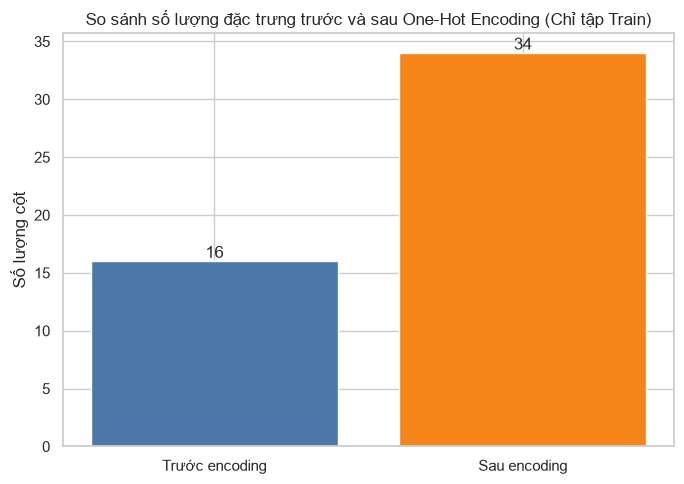

In [9]:
# Trực quan hóa số lượng đặc trưng trước & sau One-Hot Encoding
features_before_encoding = X_train.shape[1]
features_after_encoding = X_train_processed.shape[1]
print(f"Số cột trước mã hóa: {features_before_encoding}")
print(f"Số cột sau mã hóa:   {features_after_encoding}")

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["Trước encoding", "Sau encoding"],
    [features_before_encoding, features_after_encoding],
    color=["#4C78A8", "#F58518"],
)
plt.title("So sánh số lượng đặc trưng trước và sau One-Hot Encoding (Chỉ tập Train)")
plt.ylabel("Số lượng cột")
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        int(bar.get_height()),
        ha="center",
    )
plt.tight_layout()
plt.savefig(PLOT_DIR / "04_features_before_after_encoding.png", dpi=150, bbox_inches="tight")
plt.show()


Độ lệch (skewness) của các biến số (Tập Train):


,skewness
previous,45.034399
balance,8.340204
campaign,4.941861
duration,3.210882
pdays,2.616298
age,0.693738
day,0.093389


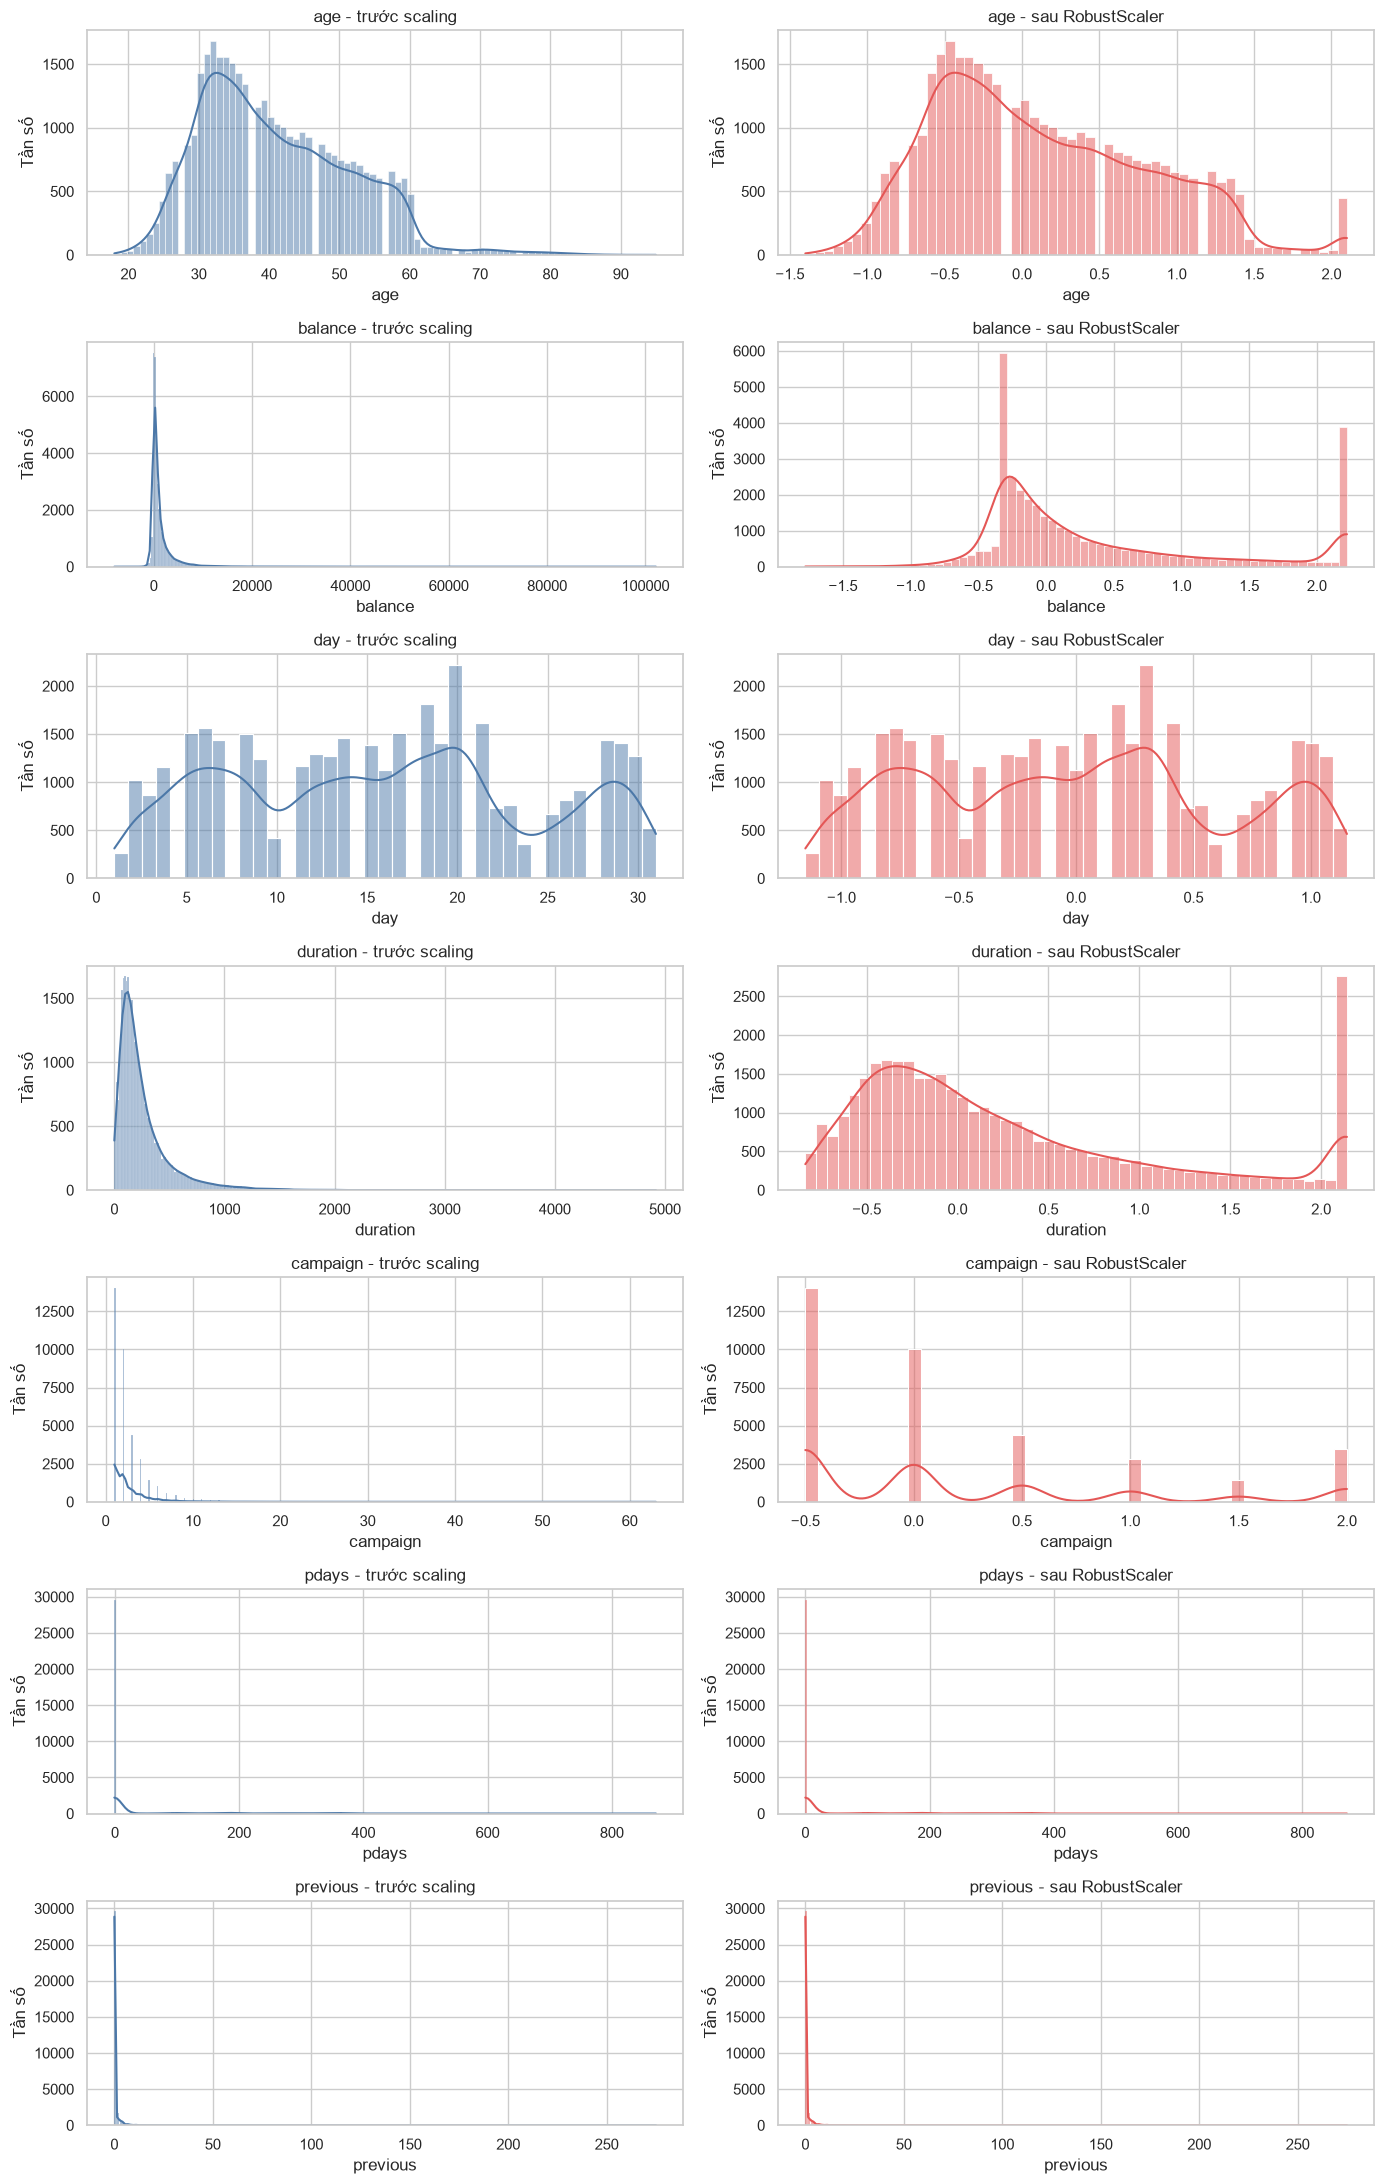

Thống kê sau RobustScaler (Tập Train):


,mean,50%,std,min,max
age,0.121658,0.0,0.693499,-1.400000,2.100000
balance,0.357277,0.0,0.867572,-1.777972,2.222028
day,-0.014003,0.0,0.640922,-1.153846,1.153846
duration,0.254580,0.0,0.820412,-0.837209,2.141860
campaign,0.196099,0.0,0.800027,-0.500000,2.000000
pdays,41.157238,0.0,100.162614,0.000000,872.000000
previous,0.581730,0.0,2.408766,0.000000,275.000000


In [10]:
# Phân phối trước & sau RobustScaler trên tập Train
skewness = X_train[numeric_columns].skew().sort_values(ascending=False)
print("Độ lệch (skewness) của các biến số (Tập Train):")
display(skewness.to_frame("skewness"))

fig, axes = plt.subplots(len(numeric_columns), 2, figsize=(14, 22))
for row, column in enumerate(numeric_columns):
    sns.histplot(X_train[column], kde=True, ax=axes[row, 0], color="#4C78A8")
    axes[row, 0].set_title(f"{column} - trước scaling")
    axes[row, 0].set_xlabel(column)
    axes[row, 0].set_ylabel("Tần số")
    sns.histplot(
        X_train_processed[column], kde=True, ax=axes[row, 1], color="#E45756"
    )
    axes[row, 1].set_title(f"{column} - sau RobustScaler")
    axes[row, 1].set_xlabel(column)
    axes[row, 1].set_ylabel("Tần số")
plt.tight_layout()
plt.savefig(PLOT_DIR / "05_distributions_before_after_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

print("Thống kê sau RobustScaler (Tập Train):")
display(X_train_processed[numeric_columns].describe().T[["mean", "50%", "std", "min", "max"]])


10 đặc trưng tương quan mạnh nhất với y (Tập Train):


,correlation_with_y
duration,0.390997
poutcome_success,0.305847
poutcome_unknown,-0.163322
contact_unknown,-0.149825
housing,-0.139432
contact_cellular,0.132642
pdays,0.100703
balance,0.094514
previous,0.088847
campaign,-0.083142


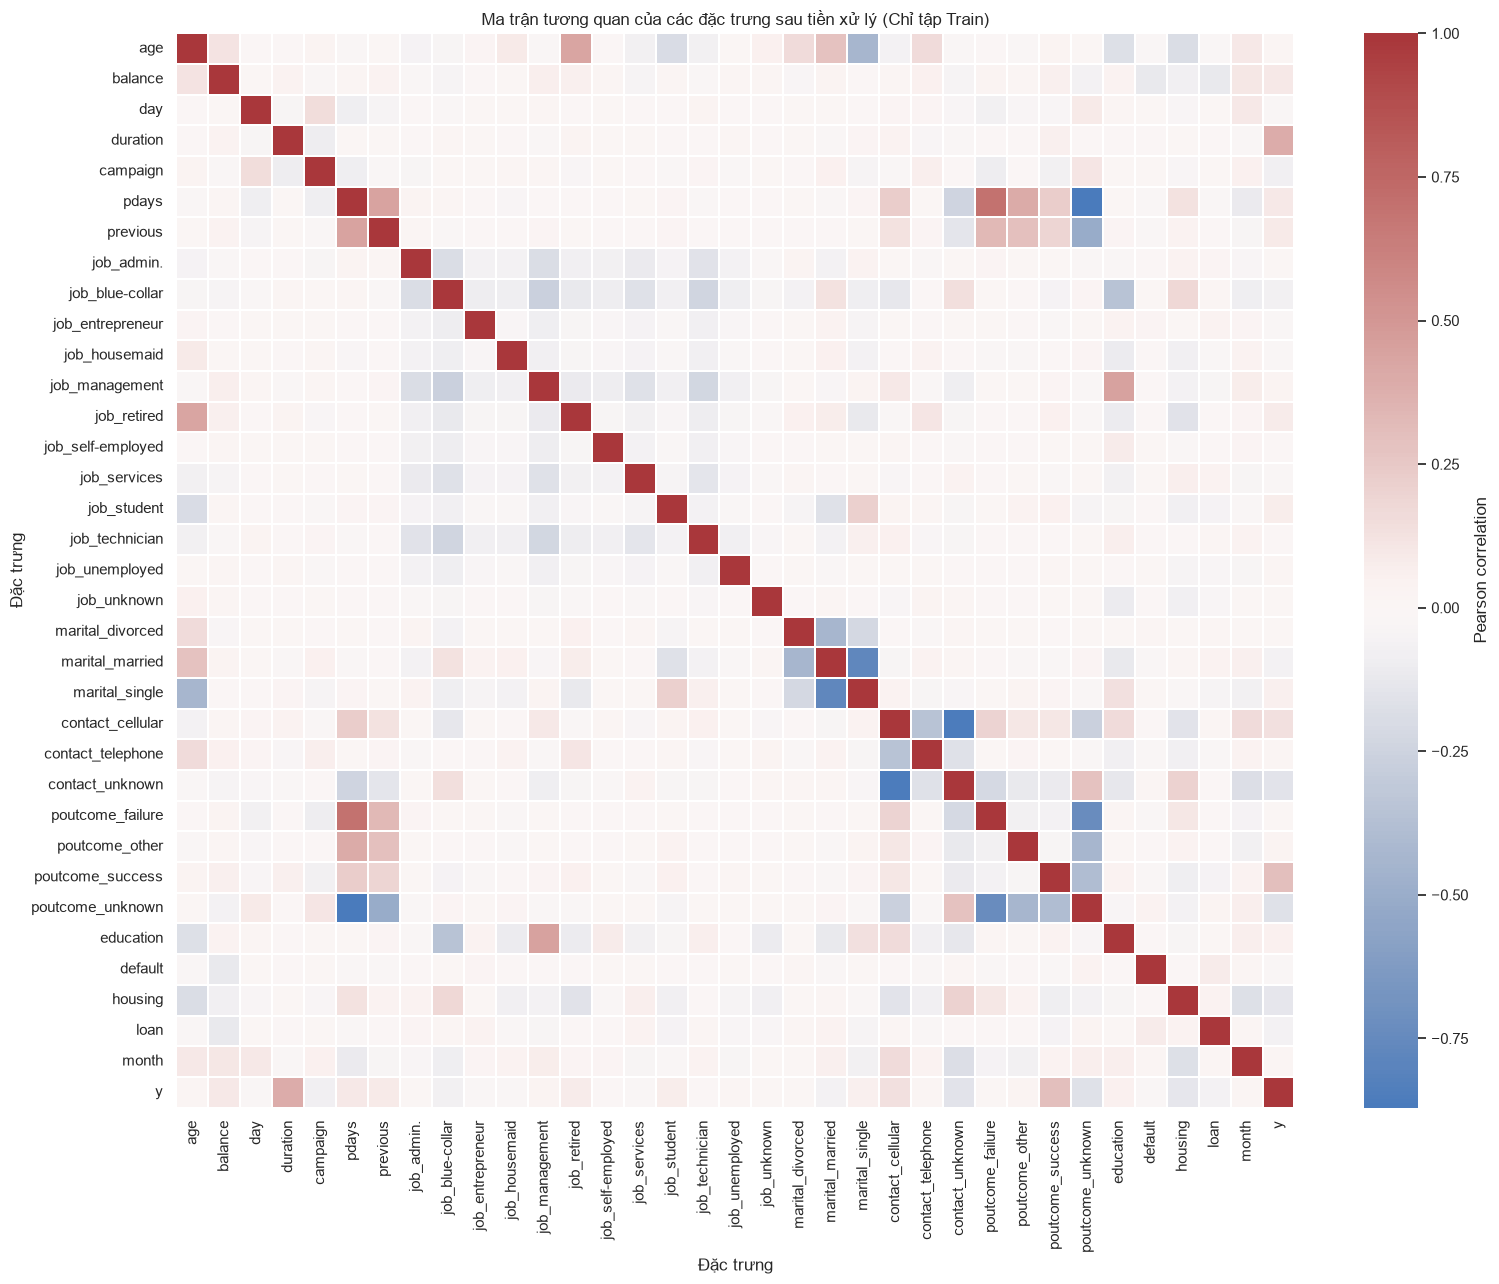

10 cặp có tương quan tuyệt đối cao nhất (Tập Train):


,,absolute_correlation
pdays,poutcome_unknown,0.870425
contact_cellular,contact_unknown,0.862627
marital_married,marital_single,0.772118
poutcome_failure,poutcome_unknown,0.736112
pdays,poutcome_failure,0.699935
previous,poutcome_unknown,0.511669
job_management,education,0.451499
marital_divorced,marital_married,0.443925
pdays,previous,0.438963
poutcome_other,poutcome_unknown,0.438824


In [11]:
# Phân tích tương quan & đa cộng tuyến (chỉ trên tập Train đã xử lý kết hợp y_train)
train_for_corr = pd.concat([X_train_processed, y_train], axis=1)
correlation_matrix = train_for_corr.corr(numeric_only=True)
target_correlation = correlation_matrix["y"].drop("y").sort_values(
    key=np.abs, ascending=False
)
print("10 đặc trưng tương quan mạnh nhất với y (Tập Train):")
display(target_correlation.to_frame("correlation_with_y").head(10))

plt.figure(figsize=(16, 13))
sns.heatmap(
    correlation_matrix,
    cmap="vlag",
    center=0,
    linewidths=0.2,
    cbar_kws={"label": "Pearson correlation"},
)
plt.title("Ma trận tương quan của các đặc trưng sau tiền xử lý (Chỉ tập Train)")
plt.xlabel("Đặc trưng")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.savefig(PLOT_DIR / "06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)
strong_pairs = (
    upper_triangle.stack()
    .abs()
    .sort_values(ascending=False)
    .to_frame("absolute_correlation")
)
print("10 cặp có tương quan tuyệt đối cao nhất (Tập Train):")
display(strong_pairs.head(10))


## Bước 5 - Xử lý mất cân bằng lớp (SMOTE duy nhất trên tập Train)

Biến mục tiêu `y` bị mất cân bằng nghiêm trọng (~88.3% `no` và ~11.7% `yes`).
- Áp dụng `SMOTE(random_state=42)` **chỉ trên `X_train_processed` và `y_train`** để tạo mẫu tổng hợp cho lớp thiểu số, đưa tỷ lệ về cân bằng 50:50.
- **Tập test (`X_test_processed`, `y_test`) giữ nguyên hoàn toàn** để phản ánh đúng phân phối thực tế của dữ liệu, đảm bảo việc đánh giá mô hình khách quan và trung thực.


Phân phối y_train ban đầu:


y
0    88.3
1    11.7
Name: percentage, dtype: float64

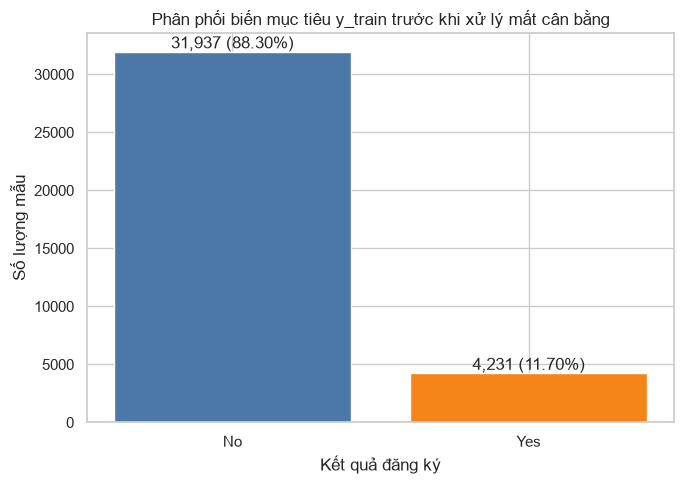

Phân phối y_train trước SMOTE:
y
0    31937
1     4231
Name: count, dtype: int64

Phân phối y_train_resampled sau SMOTE:
y
0    31937
1    31937
Name: count, dtype: int64


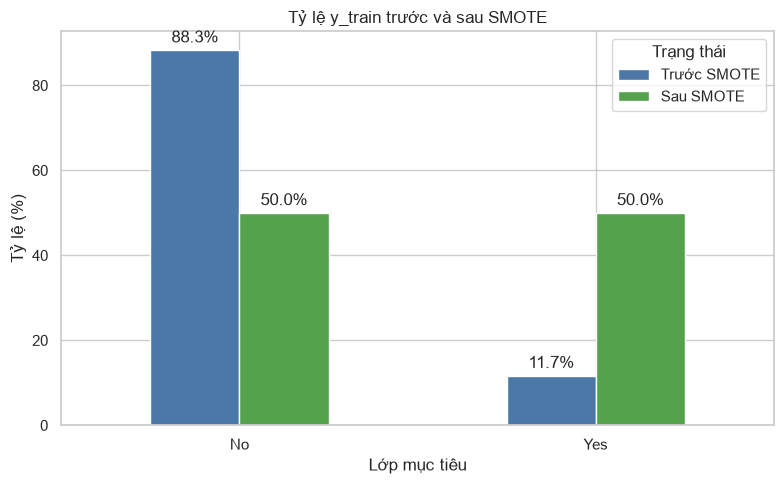

Kích thước X_train_processed: (36168, 34)
Kích thước X_train_resampled: (63874, 34)
Kích thước X_test_processed:  (9043, 34)

Tỷ lệ y_test giữ nguyên (không qua SMOTE để đảm bảo khách quan):


y
0    88.3
1    11.7
Name: percentage, dtype: float64

In [12]:
print("Phân phối y_train ban đầu:")
display(
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .rename("percentage")
)

initial_counts = y_train.value_counts().sort_index()
plt.figure(figsize=(7, 5))
bars = plt.bar(["No", "Yes"], initial_counts.values, color=["#4C78A8", "#F58518"])
plt.title("Phân phối biến mục tiêu y_train trước khi xử lý mất cân bằng")
plt.xlabel("Kết quả đăng ký")
plt.ylabel("Số lượng mẫu")
for bar, count in zip(bars, initial_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,} ({count / len(y_train) * 100:.2f}%)",
        ha="center",
        va="bottom",
    )
plt.tight_layout()
plt.savefig(PLOT_DIR / "07_target_distribution_before_smote.png", dpi=150, bbox_inches="tight")
plt.show()

smote = SMOTE(random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_processed, y_train
)
print("Phân phối y_train trước SMOTE:")
print(y_train.value_counts().sort_index())
print("\nPhân phối y_train_resampled sau SMOTE:")
print(y_train_resampled.value_counts().sort_index())

comparison_counts = pd.DataFrame(
    {
        "Trước SMOTE": y_train.value_counts().sort_index(),
        "Sau SMOTE": y_train_resampled.value_counts().sort_index(),
    },
    index=[0, 1],
)
comparison_percentages = comparison_counts.div(
    comparison_counts.sum(axis=0), axis=1
).mul(100)
comparison_plot = comparison_percentages.rename(
    index={0: "No", 1: "Yes"}
).plot(kind="bar", figsize=(8, 5), color=["#4C78A8", "#54A24B"])
comparison_plot.set_title("Tỷ lệ y_train trước và sau SMOTE")
comparison_plot.set_xlabel("Lớp mục tiêu")
comparison_plot.set_ylabel("Tỷ lệ (%)")
comparison_plot.set_xticklabels(["No", "Yes"], rotation=0)
comparison_plot.legend(title="Trạng thái")
for container in comparison_plot.containers:
    comparison_plot.bar_label(container, fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "08_train_distribution_before_after_smote.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Kích thước X_train_processed: {X_train_processed.shape}")
print(f"Kích thước X_train_resampled: {X_train_resampled.shape}")
print(f"Kích thước X_test_processed:  {X_test_processed.shape}")
print("\nTỷ lệ y_test giữ nguyên (không qua SMOTE để đảm bảo khách quan):")
display(
    y_test.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .rename("percentage")
)


## Bước 6 - Xuất dữ liệu sạch & chuẩn hóa tách biệt train/test

Thay vì xuất chung một file `cleaned_bank_data.csv`, xuất riêng biệt các tập dữ liệu để phục vụ trực tiếp cho các giai đoạn mô hình hóa tiếp theo:
- `train_processed.csv`: Tập train sạch (36,168 dòng $\times$ 35 cột), giữ nguyên phân phối mất cân bằng.
- `train_resampled.csv`: Tập train sạch đã qua SMOTE cân bằng 50:50 (63,874 dòng $\times$ 35 cột).
- `test_processed.csv`: Tập test sạch (9,043 dòng $\times$ 35 cột), transformed hoàn toàn từ bộ tham số của train.


In [13]:
train_processed = pd.concat([X_train_processed, y_train], axis=1)
train_resampled = pd.concat([X_train_resampled, y_train_resampled], axis=1)
test_processed = pd.concat([X_test_processed, y_test], axis=1)

train_processed_path = Path("train_processed.csv")
train_resampled_path = Path("train_resampled.csv")
test_processed_path = Path("test_processed.csv")

train_processed.to_csv(train_processed_path, index=False)
train_resampled.to_csv(train_resampled_path, index=False)
test_processed.to_csv(test_processed_path, index=False)

print(f"Đã lưu tập train đã xử lý:  {train_processed_path} ({train_processed.shape[0]:,} dòng x {train_processed.shape[1]} cột)")
print(f"Đã lưu tập train sau SMOTE:   {train_resampled_path} ({train_resampled.shape[0]:,} dòng x {train_resampled.shape[1]} cột)")
print(f"Đã lưu tập test đã xử lý:   {test_processed_path} ({test_processed.shape[0]:,} dòng x {test_processed.shape[1]} cột)")
print(f"\nTổng số giá trị null tập train: {int(train_processed.isna().sum().sum())}")
print(f"Tổng số giá trị null tập test:  {int(test_processed.isna().sum().sum())}")
print(f"Thư mục biểu đồ: {PLOT_DIR.resolve()}")


Đã lưu tập train đã xử lý:  train_processed.csv (36,168 dòng x 35 cột)
Đã lưu tập train sau SMOTE:   train_resampled.csv (63,874 dòng x 35 cột)
Đã lưu tập test đã xử lý:   test_processed.csv (9,043 dòng x 35 cột)

Tổng số giá trị null tập train: 0
Tổng số giá trị null tập test:  0
Thư mục biểu đồ: D:\project\ml_assign\outputs\plots
